In [ ]:
import pandas as pd

raw = pd.read_csv("house_price_bd.csv")

Load + duplicate remove

In [22]:
raw.shape

raw= raw.drop_duplicates()
print("After duplicate removal:", raw.shape)

After duplicate removal: (2931, 9)


Convert Price to a numeric value and extract Area from Location.

In [23]:
df = raw.copy()

df["Price"] = (df["Price_in_taka"].astype(str)
               .str.replace("৳", "", regex=False)
               .str.replace(",", "", regex=False)
               .astype(float))

df["Area"] = df["Location"].str.split(",").str[-1].str.strip()
df[["Price", "Area"]].head()

,Price,Area
0,39000000.0,Gulshan
1,16900000.0,Kalabagan
2,12500000.0,Dhanmondi
3,20000000.0,Bashundhara R-A
4,47500000.0,Banani


remove unnecessary row and column


In [24]:
df = df.drop(columns=["Title", "Price_in_taka", "Location", "Occupancy_status"])
df = df.dropna(subset=["Floor_area", "Area"])
print("Before outlier:", df.shape)
df.isnull().sum()

Before outlier: (2841, 7)


,0
Bedrooms,742
Bathrooms,742
Floor_no,486
Floor_area,0
City,0
Price,0
Area,0


Price per sqft


In [25]:
df["Price_per_sqft"] = df["Price"] / df["Floor_area"]
df["Price_per_sqft"].describe()

,Price_per_sqft
count,2841.000000
mean,7846.110195
std,8260.860800
min,347.222222
25%,4000.000000
50%,5500.000000
75%,7809.523810
max,97656.250000


IQR function

In [26]:
def remove_outliers_iqr(data, col):
    q1 = data[col].quantile(0.25)
    q3 = data[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    return data[(data[col] >= low) & (data[col] <= high)]

Apply IQR outlier removal separately for each city.

In [27]:
before = df.shape[0]
df_clean = df.groupby("City", group_keys=False).apply(
    lambda g: remove_outliers_iqr(g, "Price_per_sqft")
)
print("Before:", before, "After:", df_clean.shape[0])
df_clean["Price"].describe()

Before: 2841 After: 2410


/tmp/ipykernel_1113/976043597.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_clean = df.groupby("City", group_keys=False).apply(


,Price
count,2.410000e+03
mean,9.889789e+06
std,1.206957e+07
min,1.050000e+06
25%,5.000000e+06
50%,7.200000e+06
75%,1.050000e+07
max,2.200000e+08


Unique areas

In [28]:
counts = df_clean["Area"].value_counts()
rare = counts[counts < 10].index
df_clean["Area"] = df_clean["Area"].replace(rare, "Other")
print("Unique areas:", df_clean["Area"].nunique())

Unique areas: 39


Before/After chart

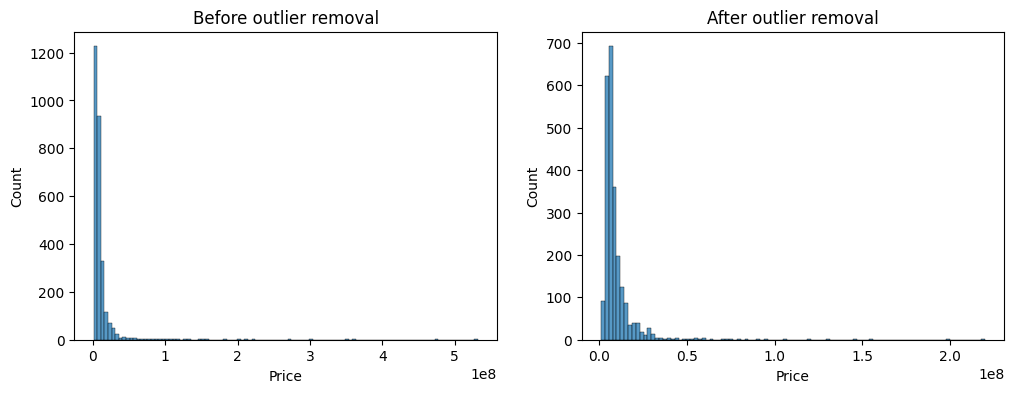

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Price"], ax=ax[0]).set_title("Before outlier removal")
sns.histplot(df_clean["Price"], ax=ax[1]).set_title("After outlier removal")
plt.show()

Clean data save

In [30]:
df_clean = df_clean.drop(columns=["Price_per_sqft"])
df_clean.to_csv("housing_clean.csv", index=False)
print(df_clean.shape)

(2410, 7)
